# Dataset Description

I have used the fortune WA_Fn-UseC_-HR-Employee-Attrition.csv dataset for this project. I have downloaded this dataset from the data world website. This data set can be downloaded from the following url –

https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset

This is a fictional data set created by IBM data scientists.

# Import Libreries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binom
from scipy.stats import randint
from scipy import stats
from scipy.stats import poisson

# Import dataset

In [3]:
data = 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

df = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


# Exploratory data analysis

Exploratory data to gain insights

### Dimension of dataset

In [4]:
df.shape

(1470, 35)

There are 1470 instances (rows) and 35 variables (columns) in the dataset

### Preview the dataset

Total rows and columns


In [5]:
df.head(5)

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


### View summary of dataset

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### Missing Values

In [7]:
df.isnull().sum()

Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole          0
YearsSince

The above command shows that there are no missing values in the data set.

This is a Binary Problem, so the Distribution of instances among 2 clases, is visualized below.

# Key Variables Definition

In [58]:
print('Age', 'Attrition', 'DailyRate', 'Department', 'Gender', 'MonthlyIncome', 'Gender')

key_variables = ['Age', 'Attrition', 'DailyRate', 'Department', 'Gender', 'MonthlyIncome']

print(df[key_variables].dtypes)

Age Attrition DailyRate Department Gender MonthlyIncome Gender
Age               int64
Attrition        object
DailyRate         int64
Department       object
Gender           object
MonthlyIncome     int64
dtype: object


Here are the variables I consider key to analyzing the probability of an employee remaining or resigning.

Cuantitative Variables: Age, DailyRate, MonthlyIncome

Cualitative Variables: Attrition, Department, Gender

**I will use 'MonthlyIncome' as the central axis of the analysis**

# Descriptive Statistics with describe() function

The describe() function gives us the count, mean, standard deviation(std), minimum, Q1(25%), median(50%), Q3(75%), IQR(Q3 - Q1) and maximun values

### Summary statistics of numerical columns

In [10]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


describe() function excludes the character columns and gives summary statisticas of numeric columns only.

### Summary statistics of character columns

In [9]:
df.describe(include=['object'])

,Attrition,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470,1470
unique,2,3,3,6,2,9,3,1,2
top,No,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1233,1043,961,606,882,326,673,1470,1054


describe() function with an argument named include along with value object (include=['object']) gives the summary statistics of the character columns

In [10]:
df.describe(include='all')

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470,1470,1470.000000,1470,1470.000000,1470.000000,1470,1470.0,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
unique,NaN,2,3,NaN,3,NaN,NaN,6,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,No,Travel_Rarely,NaN,Research & Development,NaN,NaN,Life Sciences,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1233,1043,NaN,961,NaN,NaN,606,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,36.923810,NaN,NaN,802.485714,NaN,9.192517,2.912925,NaN,1.0,1024.865306,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,NaN,NaN,403.509100,NaN,8.106864,1.024165,NaN,0.0,602.024335,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,NaN,NaN,102.000000,NaN,1.000000,1.000000,NaN,1.0,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,NaN,NaN,465.000000,NaN,2.000000,2.000000,NaN,1.0,491.250000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,NaN,NaN,802.000000,NaN,7.000000,3.000000,NaN,1.0,1020.500000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,NaN,NaN,1157.000000,NaN,14.000000,4.000000,NaN,1.0,1555.750000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000


- The describe() function with include='all' gives the summary statistics of all the columns.

- We need to add a variable named include='all' to get the summary of both numeric and character column

# Plot the Distribution

I will use the 

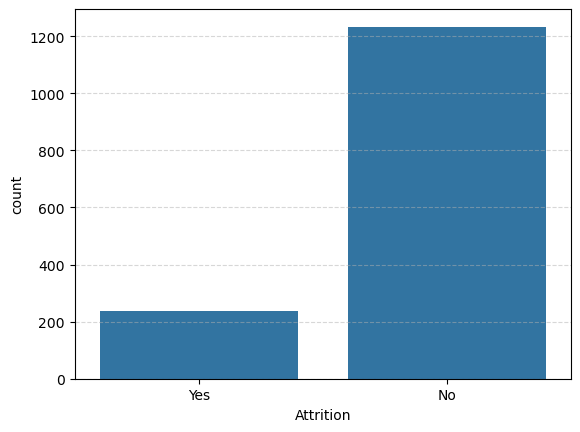

In [11]:
dataset = pd.read_csv('WA_Fn-UseC_-HR-Employee-Attrition.csv')

sns.set_style()
sns.countplot(x ='Attrition', data = dataset)

plt.grid(axis='y', linestyle='--', alpha=0.5)

### Interpretation

This count plot displays the count of observations in each category of the 'Attrition' column from the dataset. It visualizes how many employees fall into each attrition category ('Yes' or 'No') in this bar chart

### Histogram with Kernel Density Estimation (KDE) for 'MonthlyIncome'

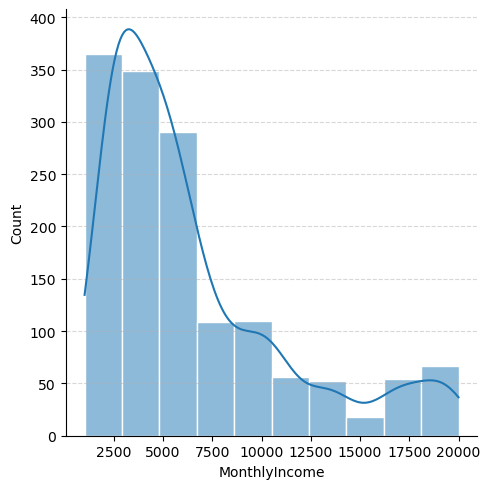

In [57]:
data = df['MonthlyIncome']

sns.displot(data, bins=10, edgecolor="white",
            kde=True, label = 'MonthlyIncome')
plt.grid(axis='y', linestyle='--', alpha=0.5)

### Interpretation

The above plot confirms that the MonthlyIncome is positively skewed

We can see a massive concentration of bars on the left (low salaries) and a long tail stretching toward 20,000 USD on the right representing top executives.

*`distplot` is a deprecated function and will be removed in a future version.
The 'hist' parameter is not a valid argument for 'displot()' in recent versions of seaborn.
In 'sns.displot()', the histogram is shown by default, so we don't need to specify 'hist=True'. The function automatically crates a histogram.*

### Boxplot of 'MonthlyIncome' segmented by 'Attrition'

<Axes: xlabel='Attrition', ylabel='MonthlyIncome'>

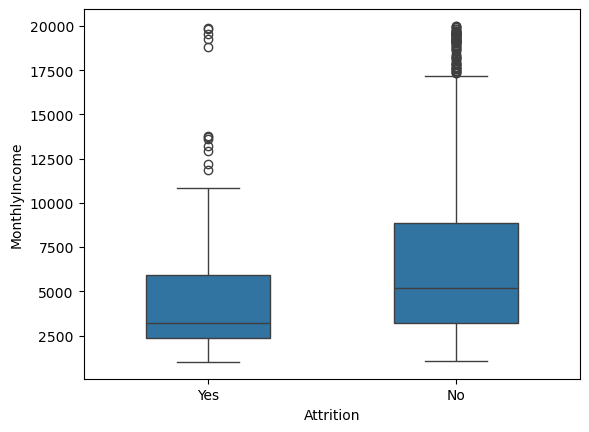

In [13]:
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', order=['Yes', 'No'], width=0.5)

### Interpretation

This Boxplot compares the Distribution of MonthlyIncome across different Attrition groups, for vizualizing salary differences between employees who left versus those who stayed.

This Boxplot also shows that the median salary for employees who left the company (Attrition = Yes) is notably lower than that of those who stayed (No). In addition, we can notice a large number of isolated dots (outliers) at the top of the group that stayed, representing stable executives with higher salaries.

### Staff Distribution by Department and Gender

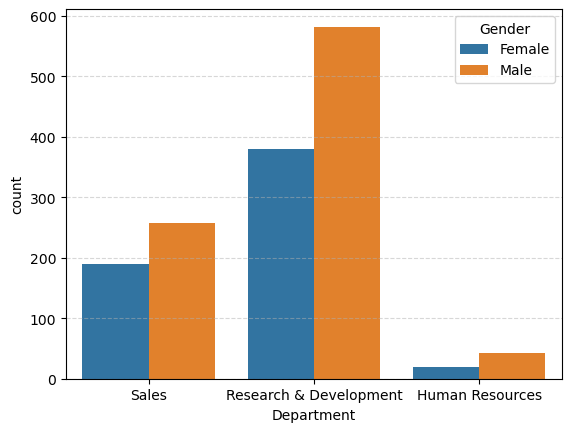

In [14]:
sns.countplot(data=df, 
              x='Department', 
              hue='Gender')

plt.grid(axis='y', linestyle='--', alpha=0.5)

The countplot provides an overview of the organization structure. It clearly shows the workforce concentration by departments (Research & Development) and highlights potential gender gaps in critical sectors like Sales and HR

# Computing:

### Measures of central Tendency

  I will compute the measures of central tendency: **Mean, Median and Mode**

### Measures of dispersion or variability

  I will compute the measures os dispersion or variability - **minimum and maximum values, range, variance, standard deviation, IQR**


 ## Measures of shape of distribution

   I will compute the measures of shape of distribution: **Skewness and Kurtosis**

 

### Variable definition

In [68]:
# I can add here the Variables that I want to use for the analysis. In this case:

cuantitative_var = ['MonthlyIncome', 'Age', 'TrainingTimesLastYear']
categorical_var = ['Attrition', 'Department', 'Gender']

#I will use 'Attrition', 'Department', 'Gender' as Categorical Valriables* to show Organization Structure in percentages


### Cuantitative Variables

In [61]:
desc = df[cuantitative_var].describe().T

In [62]:
desc['median'] = df[cuantitative_var].median()
desc['mean'] = df[cuantitative_var].mean()
desc['mode'] = df[cuantitative_var].apply(lambda x: x.mode().iloc[0])

In [63]:
desc['Q1'] = df[cuantitative_var].quantile(0.25)
desc['Q2'] = df[cuantitative_var].quantile(0.50)
desc['Q3'] = df[cuantitative_var].quantile(0.75)
desc['IQR'] = desc['Q3'] - desc['Q1']
desc['Range'] =  desc['max'] - desc['min']
desc['Variance'] = df[cuantitative_var].var()

In [64]:
desc['skewness'] = df[cuantitative_var].skew()
desc['kurtosis'] = df[cuantitative_var].kurt()

In [71]:
final_columns = ['mean', 'median', 'mode', 'std', 'Q1', 'Q2', 'Q3', 'IQR', 'min', 'max', 'Range', 'skewness', 'kurtosis', 'Variance']
final_sum = desc[final_columns].rename(columns={'std': 'Std_Dev'})
print(final_sum.round(2))

                          mean  median  mode  Std_Dev      Q1      Q2      Q3  \
MonthlyIncome          6502.93  4919.0  2342  4707.96  2911.0  4919.0  8379.0   
Age                      36.92    36.0    35     9.14    30.0    36.0    43.0   
TrainingTimesLastYear     2.80     3.0     2     1.29     2.0     3.0     3.0   

                          IQR     min      max    Range  skewness  kurtosis  \
MonthlyIncome          5468.0  1009.0  19999.0  18990.0      1.37      1.01   
Age                      13.0    18.0     60.0     42.0      0.41     -0.40   
TrainingTimesLastYear     1.0     0.0      6.0      6.0      0.55      0.49   

                          Variance  
MonthlyIncome          22164857.07  
Age                          83.46  
TrainingTimesLastYear         1.66  


### Categorical Variables

In [21]:
for var in categorical_var:
    print()
    proportion = df[var].value_counts(normalize=True) * 100
    print(proportion.round(2).astype(str) + '%')


Attrition
No     83.88%
Yes    16.12%
Name: proportion, dtype: object

Department
Research & Development    65.37%
Sales                     30.34%
Human Resources            4.29%
Name: proportion, dtype: object

Gender
Male      60.0%
Female    40.0%
Name: proportion, dtype: object


# Results and Conclusions

I used the 'MonthlyIncome' as variable for the analysis because it is usually a critical factor in Attrition. 

The results reveal an average income (mean) of 6,502.93 and Standard Deviation (SD) of 4,707.96. This SD indicates a high dispersion in salaries, reflecting disparities among different hierarchical levels or departments within the organization.

The first quartile (Q1) is at 2911.0, meaning that 25% of employees earn salary less than or equal to this amount.
The Median (Q2) was locatel at 4919.0, indicating that half of the organization earns less than this amount and the other half earns more. 

Since the mean is greater than the median, there is evidence of a positive right skewness in the distribution, we confirm this with the skewness plot above where we can see a massive concentration of bars on the left (low salaries) and a long tail stretching toward 20,000 USD on the right representing top executives. Which is characteristic of financial data where minority concentrates the highest incomes. 
The third quartile (Q3) at 8379.0, establishing that 75% of the sample earns less than that.


I find the kurtosis to be 1.01. So, it is grater than 0 (1.01 > 0): the distribution is Leotokurtic, meaning it has a higher, sharper peak and heavier tails than a normal distribution.

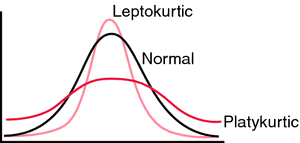


Absolute dispersion metrics show a Range of 1899.0 (the difference between minimum and maximum salary). However, to avoid distortion from extreme values, the Interquartile Range (IQR) was calculated, wich is 54.68.0. This value represents the dispersion of the central 50% of employees, providing a baseline for identify the outliers observerd in the boxplot.

Finally, the categorical Variables shows the Attrition Distribution, Department and Gender Distribution of the Structure Organization in percentages.

We can observe that 16.12% of the employees chose to resign from their job.

# Binomial Distribution

In [62]:
total_employees = 1470
attrition_yes = 237
empirical_probability = (df['Attrition'] == 'Yes').mean()

print(f'Empirical Probability of success (p): {empirical_probability: .4f}')

Empirical Probability of success (p):  0.1612


We can see here the fraction of employees have 'Attrition' equal to 'Yes', which represents the empirical probability of Attrition.

In [69]:
# Define problem parameters
n = 20        # Total number of employees in the sample
p = 0.1612    # Baseline attrition probability (16.12%)

# to Calculate the expected average (Mean)
mean = n * p
print(f"Expected average of departures: {mean:.2f} employees")

# To Calculate the exact probability of exactly 3 departures (PMF)
exact_prob_3 = stats.binom.pmf(3, n, p)
print(f"Probability of exactly 3 departures: {exact_prob_3 * 100:.2f}%")

# To Calculate the cumulative probability of 3 or fewer departures (CDF)
cumulative_prob_3 = stats.binom.cdf(3, n, p)
print(f"Probability of 3 or fewer departures: {cumulative_prob_3 * 100:.2f}%")

# To Calculate the Risk Factor (4 or more departures)
# Mathematically, P(X >= 4) is equivalent to 1 - P(X <= 3)
risk_factor = 1 - cumulative_prob_3
print(f"The Risk Factor (4 or more departures): {risk_factor * 100:.2f}%")

Expected average of departures: 3.22 employees
Probability of exactly 3 departures: 24.05%
Probability of 3 or fewer departures: 59.31%
The Risk Factor (4 or more departures): 40.69%


### Interpretation

- The Expected Average: In a group of 20 employees, the standard expectation is for 3 people to leave (the exact mathematical calculation is 3.22).
- The Most Likely Scenario: The specific outcome with the highest individual probability of occurring is that exactly 3 people resign (there is a 24.05% chance of this precise event happening).
- Margin of Safety: There is a nearly 60% probability that the situation remains manageable (meaning 3 or fewer people leave the company).
- The Risk Factor: There is a 41% risk that the turnover intensifies and 4 or more people leave, exceeding original baseline expectations.

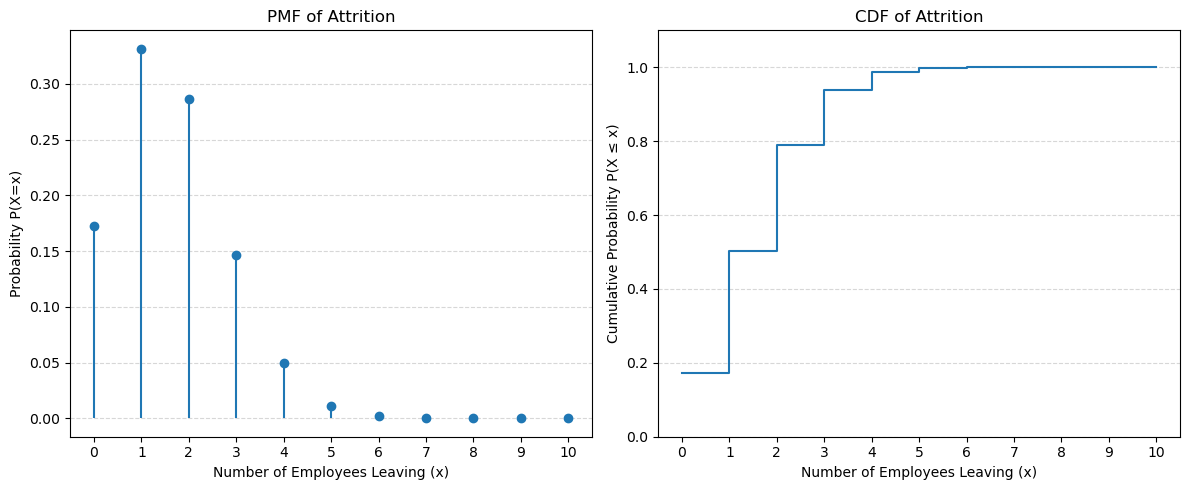

In [23]:
# Parameters for the Binomial Distribution for attrition
n_sample = 10
p_sample = 0.1612
x = np.arange(0, n_sample + 1)

# PMF and CDF using binom
pmf = binom.pmf(x, n_sample, p_sample)
cdf = binom.cdf(x, n_sample, p_sample)

# Configure the canvas for two parallel plots
plt.figure(figsize=(12, 5))

# Plot 1: PMF (Probability Mass Function)
plt.subplot(1, 2, 1)
plt.stem(x, pmf, basefmt=' ')  # Fixed typo: setm -> stem
plt.title('PMF of Attrition')
plt.xlabel('Number of Employees Leaving (x)')
plt.ylabel('Probability P(X=x)')  # Fixed typo: ply -> plt
plt.xticks(x)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Plot 2: CDF (Cumulative Distribution Function)
plt.subplot(1, 2, 2)
plt.step(x, cdf, where='post')
plt.title('CDF of Attrition')
plt.xlabel('Number of Employees Leaving (x)')
plt.ylabel('Cumulative Probability P(X ≤ x)')
plt.ylim(0, 1.1)
plt.xticks(x)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


### Results and Interpretation

Plot 1: PMF (Probability Mass Function)

- It shows the exact probability for each specific number of resignations isolated on its own.
- We can see that the highest line peaks at x = 1 with 33.14%. This means that in a small group of just 10 people, the single most likely scenario is for exactly 1 person to resign. The second highest bar will be for 2 people (28.66%).

Plot 2: CDF (Cumulative Distribution Function)

- It shows the probability that a specific number of people or fewer will leave (it dynamically accumulates the previous percentages).
- We can see that the step at x = 1 already scales past the halfway mark to reach 50.38%. By the time you reach x = 3, the staircase is sitting almost completely against the ceiling at 93.72%. This visually tells the HR team there is a 93.7% statistical certainty that no more than 3 people will leave within that group of 10.

# Poison Distribution

The variable 'TrainingTimesLastYear' will be used for this analysis. The Poisson distribution is ideal for modeling the number of times an independent event occurs within a fixed timeframe under stable conditions. Since employee training can be viewed as a discrete event distributed over time, this variable is well-suited to calculate the probability of an employee being trained during the year.

In [24]:
# First I calculate the mean of training sessions from the dataset

mean = df['TrainingTimesLastYear'].mean()

print(f'Mean: {mean: .4f}')

Mean:  2.7993


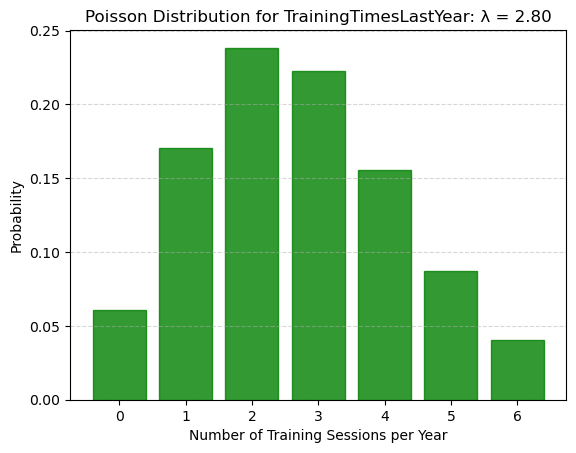

In [30]:
lambda_value = 2.7993  # Real historical mean of training session
# Define the plot range to end exactly at 6 (the company's maximum recorded value)
k = np.arange(0, 7)    # Number of possible training sessions per year (from 0 to 6)

# Poisson probability mass function (PMF)
poisson_pmf = poisson.pmf(k, lambda_value)

# Plot the Poisson Distribution

plt.bar(k, poisson_pmf, color='green', edgecolor='green', alpha=0.8)
plt.title(f'Poisson Distribution for TrainingTimesLastYear: λ = {lambda_value:.2f}')
plt.xlabel('Number of Training Sessions per Year')
plt.ylabel('Probability')
plt.xticks(k)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### Results and Interpretation

- Peak Probability: The most likely number of training sessions an employee takes in a year is 2 sessions (23.84%), closely followed by 3 sessions (22.25%).
- Extreme Values: There is a 6.09% chance an employee takes 0 sessions, and a 4.07% chance they reach the recorded maximum of exactly 6 sessions.
- Positive skewness to the right. Because the average of Training Sessions during the year is 2.77. It has a longer tail toward the right, which demonstrates that the variable is discrete and negative training sessions do not exist, but an employee could receive many training sessions (6) in one year.

# Theorical Case / Large Samples

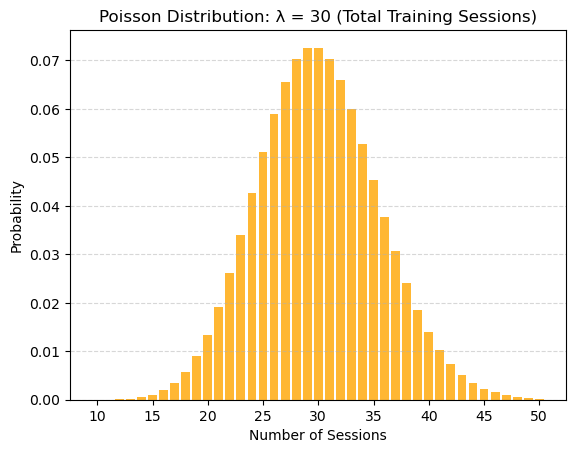

In [52]:
# Parameters for Theorical Case
lambda_large = 30  # Average number of Training Sessions
k_large = np.arange(0, 51)  # Number of possible Sessions (0 to 50)

# Poisson probability mass function for Large Training Sessions
poisson_pmf_large = poisson.pmf(k_large, lambda_large)

# Plot the Poisson distribution for Training Sessions

plt.bar(x_large, y_large, color="orange", edgecolor="none", alpha=0.8, label="Poisson (λ=30)",)
plt.title('Poisson Distribution: λ = 30 (Total Training Sessions)')
plt.xlabel('Number of Sessions')
plt.ylabel('Probability')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### Results and Interpretation

- We can see here that when simulating a scenario with large parameter (λ = 30), de distribution completely changes it shape. The bars become symmetrical around the value 30.
- This demonstrates the Poisson to the Normal Distribution, when the parameter is large enough, the discrete Poisson Distribution behaves like a Continuous Normal Distribution. 


# Conclusions

- Real Case Interpretation: This demonstrates that the company's development is standardzised, the majority of the workforce receives between 2 and 3 training sessions per year. Extreme scenarios (untrained employees or over-trained staff with more than 6 courses) are statistical anomalies with a combined probability of less than 5%.
  
- Theoretical Case Interpretation: This reflects an environment of "High Specialization" or intensive continuous learning. Because the average is so high (30), the constraint of a "zero minimum" stops affecting the shape of the graph. The probability of anyone taking fewer than 10 training sessions is practicly 0%, meaning employee behavior here becomes entirely predictable under a smooth normal curve.

# Normal Distribution

To analyze the Normal Distribution, I will use the employees' Age variable because is a continuous variable which tends to be naturally and symmetrically distzributed.

In [120]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats

In [133]:
data = 'WA_Fn-UseC_-HR-Employee-Attrition.csv'

In [ ]:
min_age = df['Age'].min()
max_age = df['Age'].max()
mean_age = df['Age'].mean()
std_age = df['Age'].std()
skewness = df['Age'].skew()
kurtosis = df['Age'].kurt()

print(f'min age: {min_age} years')
print(f'max age: {max_age} years')
print(f'Standard deviation: {std_age:.2f} years')
print(f'skewness: {skewness:.2f}')
print(f'kurtosis: {kurtosis:.2f}')

#check the data es normaly distributed or not using histogram

# Code for Employee Age Normal Distribution
# Create a sequence with uniform intervals for the x-axis
x_axis = np.linspace(18, 60, 1000)


# Calculate the theoretical probability that an employee is older than 30 years old
probability_older_30 = stats.norm.sf(30, mean_age, std_age)

print(f"Theorical Probability that an employee is older than 30: {probability_older_30:.4f}")
print(f"That means approximately {probability_older_30 * 100:.2f}% of the employees are older than 30 years.")

# To Plot the distribution histogram
plt.hist(df['Age'], bins=30, density=True, color='green', edgecolor='black', alpha=0.6, label='Real Data')

# Code to calculate the Probability density function (PDF). 

y_theoretical = stats.norm.pdf(x_axis, mean_age, std_age) 

    #stats.norm Indicates the use of a Normal Distribution (Gaussian Bell)
    #.pdf() Calculates the density of each Age

# To Plot the theoretical bell curve line over the histogram
plt.plot(x_axis, y_theoretical, color='red', linewidth=2.5, label='Theoretical Curve')

# Add titles and labels
plt.title('Normal Distribution - Employee Age')
plt.xlabel('Age (Years)')
plt.ylabel('Density')
plt.legend()
plt.grid(axis='y', alpha=0.3) # Added minor grid lines for better scannability

plt.xlim(18, 60)
plt.show()

I used the variable 'Age' for this analysis and compute:

- Descriptive Metrics: 
    - Measures of central Tendency: **mean, median and mode**
    - Measures of dispersion or variability: **minimum and maximum values and standard deviation**
    - Measures of shape of distribution: **Skewness and Kurtosis**
- Theorical Probability and Percentage that an employee is older than 30 years


### Results and Interpretation

- The vast majority ow employees are between 28 and 46 years old (the average age is 36.9 years, and the Standar Deviation (SD) is 9 years above or below this)
- The statistics model indicates that approximately 77.5% of all staff are over 30 years old
- Although ages are well distributed, the chart shows very noticeable clusters of employees at 28, 33 and 35 years old
- There are very few employees at the far ends of the chart: meaning there are very young workers (close to 18-20 years old) and few very old workers (clore to the retirement age of 60 years)